# 03. Difusión simple: la media de los cuatro vecinos

Es el primer algoritmo de restauración del trabajo. Se rellena el hueco **repitiendo la media de los cuatro vecinos** de cada píxel, solo dentro del hueco:

$$I^{t+1}(p)=\frac14\sum_{q\in N_4(p)} I^{t}(q),\qquad p\in\Omega$$

donde $\Omega$ es el hueco, $N_4(p)$ son los cuatro vecinos de $p$ (arriba, abajo, izquierda y derecha) e $I^t$ es la imagen en la iteración $t$. Los píxeles conocidos no cambian nunca.

Esta fórmula es una **propuesta nuestra** como punto de partida: es la iteración más sencilla de la difusión. No es el método de Bertalmio et al. ni aparece en el artículo base. Se usa como versión base y como punto de comparación para el método de Bertalmio.

## Cómo funciona el algoritmo

1. Se rellena el hueco con un valor de partida: la media de los píxeles conocidos de alrededor.
2. Se repite: cada píxel del hueco pasa a valer la media de sus cuatro vecinos, calculada con los valores de la iteración anterior.
3. Se para cuando ningún píxel del hueco cambia más que una tolerancia pequeña, o al llegar a un número máximo de iteraciones.

Si la imagen es en color, cada canal (R, G y B) se trata por separado. Como la media de un canal solo usa ese canal, se aplica a la matriz entera de una vez.

El código está en `src/difusion.py`: `un_paso` hace una iteración y `difusion_simple` repite hasta parar.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

import mascaras as m
import metricas as k
import difusion as d

## 1. Comprobaciones

Antes de usarlo con fotos, comprobamos que hace lo que dice la fórmula.

### Una iteración, a mano

Una imagen de 3×3 con el píxel central como hueco. Sus cuatro vecinos son 20, 40, 60 y 80, así que su media es $(20+40+60+80)/4=50$.

In [2]:
pequena = np.array([[10, 20, 30],
                    [40,  0, 60],
                    [70, 80, 90]], dtype=np.float64)
hueco_centro = np.zeros((3, 3), dtype=bool)
hueco_centro[1, 1] = True

despues = d.un_paso(pequena, hueco_centro)
print("Valor del centro tras una iteración:", despues[1, 1], "(a mano: 50)")
assert despues[1, 1] == 50
assert (despues[~hueco_centro] == pequena[~hueco_centro]).all()

Valor del centro tras una iteración: 50.0 (a mano: 50)


### Contra una versión escrita píxel a píxel

`un_paso` hace todas las medias a la vez con operaciones sobre matrices. Para asegurarnos de que coincide con la fórmula, la comparamos con otra versión escrita con bucles, un píxel cada vez y mirando los cuatro vecinos uno por uno, con 10 iteraciones sobre una imagen de 8×8 con números al azar.

In [3]:
def referencia_con_bucles(imagen, mascara, iteraciones):
    alto, ancho = imagen.shape
    actual = imagen.copy()
    for _ in range(iteraciones):
        siguiente = actual.copy()
        for fila in range(alto):
            for columna in range(ancho):
                if mascara[fila, columna]:
                    suma = 0
                    for cambio_fila, cambio_columna in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                        # Si el vecino se sale de la imagen, se repite el del borde.
                        f = min(max(fila + cambio_fila, 0), alto - 1)
                        c = min(max(columna + cambio_columna, 0), ancho - 1)
                        suma = suma + actual[f, c]
                    siguiente[fila, columna] = suma / 4
        actual = siguiente
    return actual

generador = np.random.default_rng(0)
azar = generador.integers(0, 256, (8, 8)).astype(np.float64)
hueco_azar = np.zeros((8, 8), dtype=bool)
hueco_azar[2:5, 3:6] = True
hueco_azar[0, 0] = True          # uno también en la esquina, donde faltan vecinos

con_matrices = azar.copy()
for _ in range(10):
    con_matrices = d.un_paso(con_matrices, hueco_azar)

con_bucles = referencia_con_bucles(azar, hueco_azar, 10)
print("¿Dan lo mismo las dos versiones?", np.allclose(con_matrices, con_bucles))
assert np.allclose(con_matrices, con_bucles)

¿Dan lo mismo las dos versiones? True


### Una rampa se restaura exactamente

Una imagen en la que el valor sube de forma lineal por columnas (0, 10, 20, ...) es un caso especial: la media de los cuatro vecinos de cada píxel es el propio píxel, así que la rampa es una solución exacta. Si le hacemos un hueco y lo rellenamos, debe volver a salir la misma rampa.

In [4]:
columnas = np.arange(12) * 10
rampa = np.tile(columnas, (7, 1)).astype(np.uint8)

hueco_rampa = np.zeros((7, 12), dtype=bool)
hueco_rampa[2:5, 2:10] = True
rampa_danada = m.aplicar_mascara(rampa, hueco_rampa)

rampa_restaurada, usadas = d.difusion_simple(rampa_danada, hueco_rampa)
print("Iteraciones usadas:", usadas)
print("Fila central restaurada:", rampa_restaurada[3])
print("Fila central real      :", rampa[3])
assert np.abs(rampa_restaurada.astype(int) - rampa.astype(int)).max() <= 1

Iteraciones usadas: 25
Fila central restaurada: [  0  10  20  30  40  50  60  70  80  90 100 110]
Fila central real      : [  0  10  20  30  40  50  60  70  80  90 100 110]


### Otras propiedades

- Una imagen de un solo color debe quedar del mismo color.
- Los píxeles conocidos no deben cambiar.
- El resultado tiene el mismo tipo de datos que la entrada.

In [5]:
plana = np.full((20, 30, 3), 100, dtype=np.uint8)
hueco_plana = np.zeros((20, 30), dtype=bool)
hueco_plana[5:10, 5:12] = True
plana_restaurada, _ = d.difusion_simple(m.aplicar_mascara(plana, hueco_plana, 0), hueco_plana)
print("Imagen plana restaurada vale 100 en todas partes:", bool((plana_restaurada == 100).all()))
assert (plana_restaurada == 100).all()
assert plana_restaurada.dtype == np.uint8

azar_color = generador.integers(0, 256, (20, 30, 3)).astype(np.uint8)
hueco_color = np.zeros((20, 30), dtype=bool)
hueco_color[8:12, 10:20] = True
restaurada_color, _ = d.difusion_simple(azar_color, hueco_color)
print("Los píxeles conocidos no han cambiado:", bool((restaurada_color[~hueco_color] == azar_color[~hueco_color]).all()))
assert (restaurada_color[~hueco_color] == azar_color[~hueco_color]).all()

Imagen plana restaurada vale 100 en todas partes: True
Los píxeles conocidos no han cambiado: True


## 2. Paso a paso sobre una foto

La misma foto de las pruebas anteriores, con un hueco redondo de radio 20 sobre una zona con detalle. Vemos el resultado tras 1, 2, 5, 20, 100 y 500 iteraciones, y cómo baja el error del hueco respecto a la foto original.

iteraciones   MSE del hueco
          1          2037.5
          2          1994.6
          5          1942.7
         20          1912.8
        100          1960.2


        500          2022.5


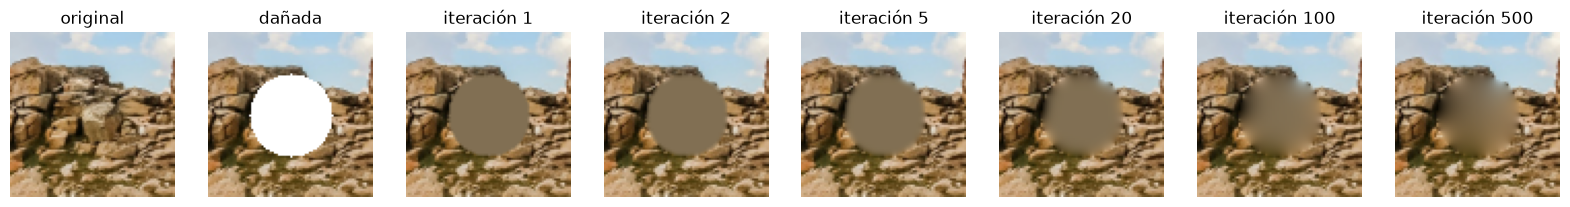

In [6]:
imagen = cv.imread("../images/originales/photo-1431315906474-0e7a186c0304.jpg")
imagen = cv.cvtColor(imagen, cv.COLOR_BGR2RGB)
escala = 512 / max(imagen.shape[:2])
imagen = cv.resize(imagen, (round(imagen.shape[1] * escala), round(imagen.shape[0] * escala)), interpolation=cv.INTER_AREA)
forma = imagen.shape[:2]

centro = (205, 330)
mascara = m.mascara_circular(forma, 20, centro)
danada = m.aplicar_mascara(imagen, mascara)
ventana = (slice(centro[0] - 40, centro[0] + 40), slice(centro[1] - 40, centro[1] + 40))

pasos = [1, 2, 5, 20, 100, 500]

plt.figure(figsize=(20, 3.6))
plt.subplot(1, len(pasos) + 2, 1)
plt.imshow(imagen[ventana])
plt.title("original")
plt.axis("off")
plt.subplot(1, len(pasos) + 2, 2)
plt.imshow(danada[ventana])
plt.title("dañada")
plt.axis("off")

print("iteraciones   MSE del hueco")
for numero, n in enumerate(pasos):
    parcial, _ = d.difusion_simple(danada, mascara, iteraciones=n, tolerancia=0)
    print(f"{n:11d}   {k.mse(imagen, parcial, mascara):13.1f}")
    plt.subplot(1, len(pasos) + 2, numero + 3)
    plt.imshow(parcial[ventana])
    plt.title(f"iteración {n}")
    plt.axis("off")
plt.show()

Qué se ve:

- Al principio el hueco es una mancha de un solo color, y poco a poco el color de los bordes va entrando hacia el centro.
- Hacia las 100 iteraciones ya casi no cambia más: el relleno es una transición suave entre los bordes. No aparecen los detalles de las rocas que había debajo, porque la media solo sabe suavizar.
- El error del hueco baja al principio (de 2037 a unos 1913 en la iteración 20) y después **sube un poco** (hasta 2022 en la 500). Es un dato de esta imagen y esta zona, pero avisa de que repetir más iteraciones no significa parecerse más a la original: el método converge a una solución suave, no a la verdadera.

## 3. Donde debe funcionar bien: arañazos y motas

Un arañazo horizontal, otro diagonal y ocho motas pequeñas, todo en una sola máscara. Medimos el error y el tiempo (media de 3 ejecuciones).

Hueco: 2505 píxeles (1.40 % de la imagen)
Iteraciones: 94   Tiempo medio: 0.332 s
dañada      MSE hueco  17257.0  PSNR hueco   5.76 dB  MSE imagen   241.23  PSNR imagen  24.31 dB
restaurada  MSE hueco    410.5  PSNR hueco  22.00 dB  MSE imagen     5.74  PSNR imagen  40.54 dB


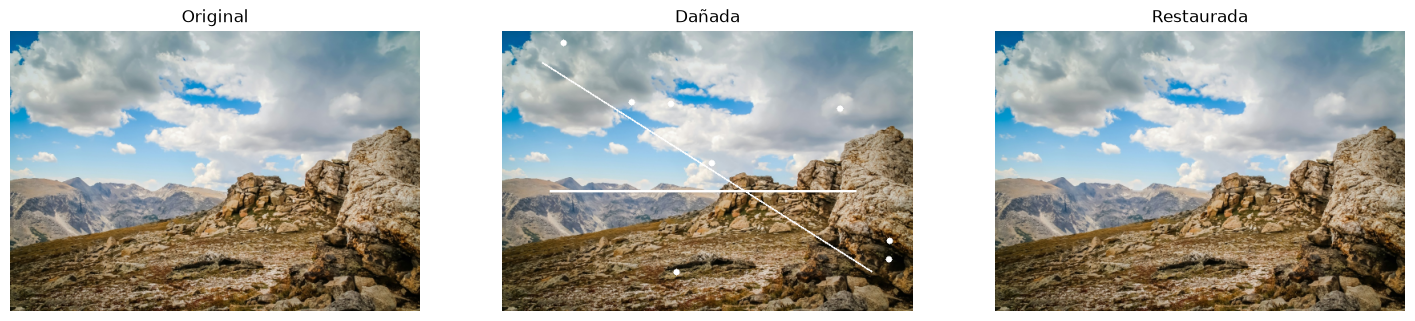

In [7]:
mascara_finos = (m.mascara_aranazo(forma, (200, 60), (200, 440), 3)
                 | m.mascara_aranazo(forma, (40, 50), (300, 460), 2)
                 | m.mascara_motas(forma, 8, 4, semilla=1))
danada_finos = m.aplicar_mascara(imagen, mascara_finos)

(restaurada_finos, usadas), tiempo, _ = k.cronometrar(d.difusion_simple, danada_finos, mascara_finos, repeticiones=3)

print(f"Hueco: {mascara_finos.sum()} píxeles ({m.porcentaje_hueco(mascara_finos):.2f} % de la imagen)")
print(f"Iteraciones: {usadas}   Tiempo medio: {tiempo:.3f} s")
for nombre, im in [("dañada", danada_finos), ("restaurada", restaurada_finos)]:
    r = k.evaluar(imagen, im, mascara_finos)
    print(f"{nombre:11s} MSE hueco {r['mse_hueco']:8.1f}  PSNR hueco {r['psnr_hueco']:6.2f} dB  MSE imagen {r['mse_imagen']:8.2f}  PSNR imagen {r['psnr_imagen']:6.2f} dB")

plt.figure(figsize=(18, 4.5))
for numero, (titulo, im) in enumerate([("Original", imagen), ("Dañada", danada_finos), ("Restaurada", restaurada_finos)]):
    plt.subplot(1, 3, numero + 1)
    plt.imshow(im)
    plt.title(titulo)
    plt.axis("off")
plt.show()

En esta máscara el hueco es solo el 1,4 % de la imagen, y el error del hueco baja de 17257 (blanco) a 410 con la media. El PSNR de la imagen entera sube de 24 dB a unos 40 dB. A simple vista, el arañazo y las motas casi han desaparecido, porque cada píxel dañado tiene vecinos conocidos muy cerca.

## 4. Cuando el hueco crece

Huecos cuadrados de lado 4, 8, 16, 32 y 64 en el centro de la foto. Para cada uno: las iteraciones hasta parar, el tiempo medio de 3 ejecuciones y el error sobre el hueco.

Es una primera versión del experimento de la hipótesis H1 (la difusión se degrada al crecer el hueco), con una sola imagen.

lado   iteraciones   tiempo (s)   MSE hueco   PSNR hueco (dB)
   4            16       0.0014         9.3             38.45
   8            42       0.0026        30.3             33.31


  16           102       0.0086        47.0             31.41


  32           260       0.0513       198.6             25.15


  64           943       0.6232       734.7             19.47


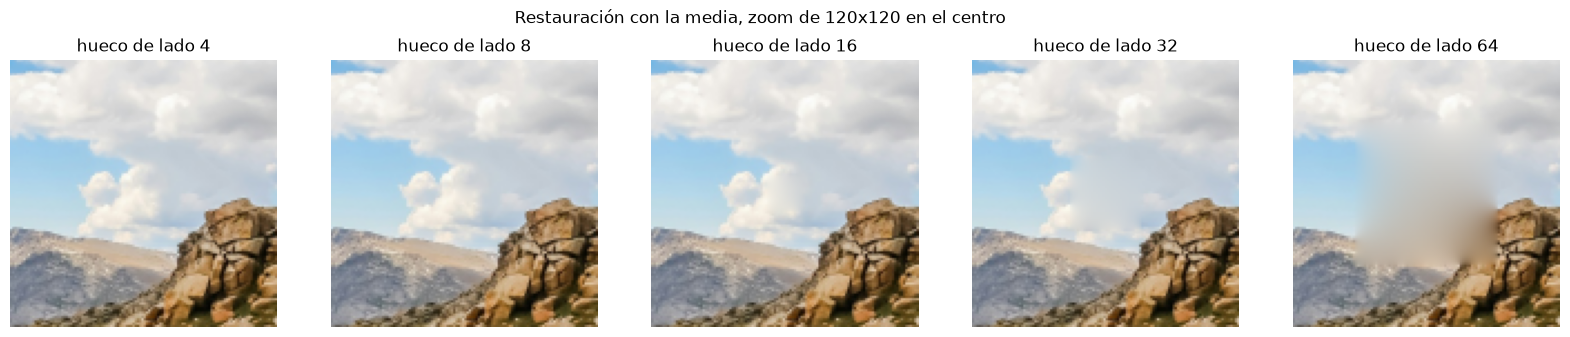

In [8]:
lados = [4, 8, 16, 32, 64]
resultados = []

print("lado   iteraciones   tiempo (s)   MSE hueco   PSNR hueco (dB)")
for lado in lados:
    mascara_c = m.mascara_cuadrada(forma, lado)
    danada_c = m.aplicar_mascara(imagen, mascara_c)
    (restaurada_c, usadas_c), tiempo_c, _ = k.cronometrar(d.difusion_simple, danada_c, mascara_c, repeticiones=3)
    error = k.mse(imagen, restaurada_c, mascara_c)
    calidad = k.psnr(imagen, restaurada_c, mascara_c)
    resultados.append((lado, danada_c, restaurada_c))
    print(f"{lado:4d}   {usadas_c:11d}   {tiempo_c:10.4f}   {error:9.1f}   {calidad:15.2f}")

fila_c, columna_c = forma[0] // 2, forma[1] // 2
zoom = (slice(fila_c - 60, fila_c + 60), slice(columna_c - 60, columna_c + 60))
plt.figure(figsize=(20, 3.8))
for numero, (lado, _, restaurada_c) in enumerate(resultados):
    plt.subplot(1, len(resultados), numero + 1)
    plt.imshow(restaurada_c[zoom])
    plt.title(f"hueco de lado {lado}")
    plt.axis("off")
plt.suptitle("Restauración con la media, zoom de 120x120 en el centro")
plt.show()

Qué se ve:

- **El error crece con el tamaño del hueco**: el MSE del hueco pasa de 9 con un cuadrado de lado 4 a unos 735 con uno de lado 64, y el PSNR baja de unos 38 a unos 19 dB.
- **En las imágenes**, los huecos de 4 a 16 casi no se notan. El de 32 ya deja una zona lisa en la nube, y el de 64 es una mancha borrosa que no continúa ni el borde de la roca ni el de la nube.
- **El tiempo crece mucho más deprisa que el hueco**: de 16 iteraciones y poco más de un milisegundo con el lado 4, a unas 940 iteraciones y más de medio segundo con el lado 64. Cuanto más grande es el hueco, más iteraciones hacen falta para que la información de los bordes llegue al centro, y cada iteración también tiene más píxeles que calcular.

Esto va en la línea de lo que dice el artículo base sobre la difusión (da buen resultado en huecos pequeños y se vuelve borrosa en los grandes), y es lo que vamos a medir con más imágenes en la Fase 3.

## Resumen

- `un_paso` hace una iteración de la media de los cuatro vecinos, solo en el hueco, y `difusion_simple` repite hasta que el cambio es menor que una tolerancia.
- Las comprobaciones pasan: una iteración a mano da 50, la versión con matrices coincide con la de bucles píxel a píxel, una rampa lineal se restaura exactamente, una imagen plana queda plana y los píxeles conocidos no cambian.
- Con arañazos y motas el resultado es muy bueno (sección 3: el PSNR de la imagen sube de 24 a 40 dB), y al crecer el hueco empeora, tanto en error como en tiempo (sección 4).
- Esto es el **producto mínimo viable**: foto sana, máscara, restauración y métricas, de principio a fin.
- Siguiente paso: la propagación a lo largo de las isófotas de Bertalmio et al., en `src/difusion.py`.